# Plasma lens from file example

Configures the COMSOL field maps in the constructor; the maps load automatically when first used.


In [1]:
import numpy as np
from abel import *

## Define the beamline and lens

In [2]:
# define beam
source = SourceBasic()
source.charge = -100e-12
source.energy = 50e6
source.rel_energy_spread = 0.01
source.bunch_length = 400e-6
source.emit_nx = source.emit_ny = 5e-6
source.beta_x = source.beta_y = 10
source.num_particles = 10000
source.length = 3
source.jitter.x = source.jitter.y = 100e-6
source.jitter.xp = source.jitter.yp = 0.01e-3

# define the RF accelerator
rf_accelerator = RFAcceleratorBasic()
rf_accelerator.nom_energy_gain = 200e6
rf_accelerator.length = 200

# define the BDS
bds = BeamDeliverySystemBasic()
bds.beta_x = bds.beta_y = 0.2
bds.length = 5

# define linac
linac = ConventionalLinac()
linac.source = source
linac.rf_accelerator = rf_accelerator
linac.bds = bds

# define the plasma lens

plasma_lens = PlasmaLensFromFile()
plasma_lens.length = 0.02 # [m]
plasma_lens.discharge_time = 135e-9 #[s]
plasma_lens.num_slice = 30
plasma_lens.external_magnetic_field_y = 300e-3 # [T]
plasma_lens.imported_magnetic_field_polarity = -1
plasma_lens.filename_Bx = "input_files/Bx.txt"
plasma_lens.filename_By = "input_files/By.txt"


# define the spectrometer
spectrometer = SpectrometerBasicCLEAR()
spectrometer.use_otr_screen = True

# assemble 
experiment = ExperimentAPL()
experiment.linac = linac
experiment.plasma_lens = plasma_lens
experiment.spectrometer = spectrometer

## Plot the imported and total field maps

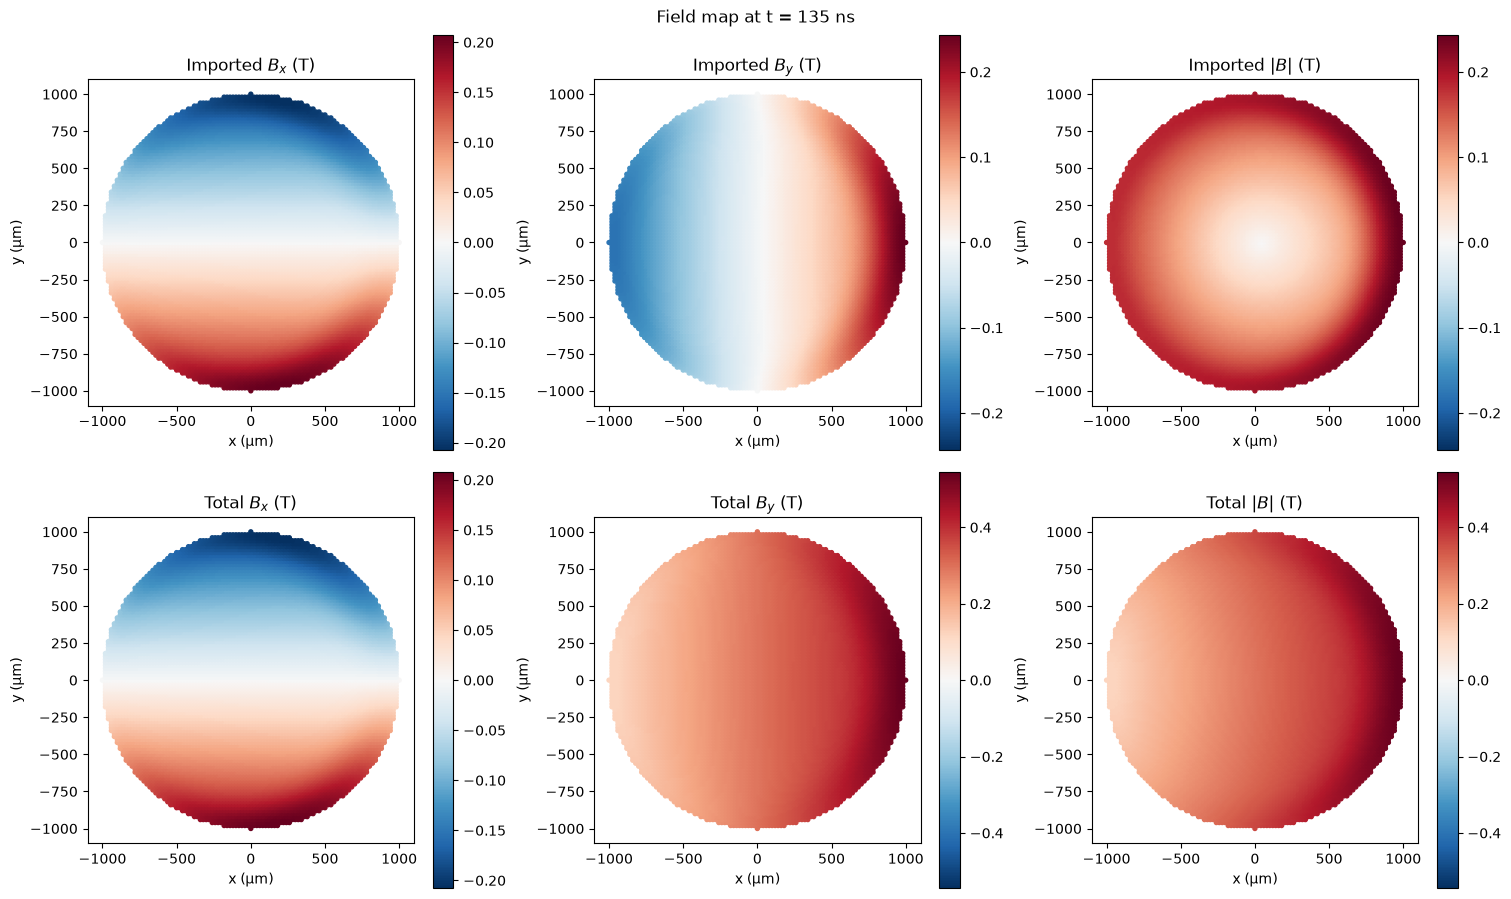

In [3]:
plasma_lens.plot_field_map()

## Run and scan the vertical lens offset

In [4]:
experiment.run('plasmalens_from_file_run',
              num_shots=1, parallel=True, overwrite=True)

Output()

In [5]:
# scan the plasma lens horizontal offset
experiment.scan(
    'plasmalens_fromfile_offset_scan',
    lambda obj, val: (setattr(obj.plasma_lens, 'offset_x', val)
                      or setattr(obj.plasma_lens, 'offset_y', 0) or obj),
    np.linspace(-plasma_lens.get_map_radius(), plasma_lens.get_map_radius(), 21),
    label='Plasma lens horizontal offset (um)', scale=1e-6,
    num_shots_per_step=5, parallel=True, overwrite=True,
)



Output()

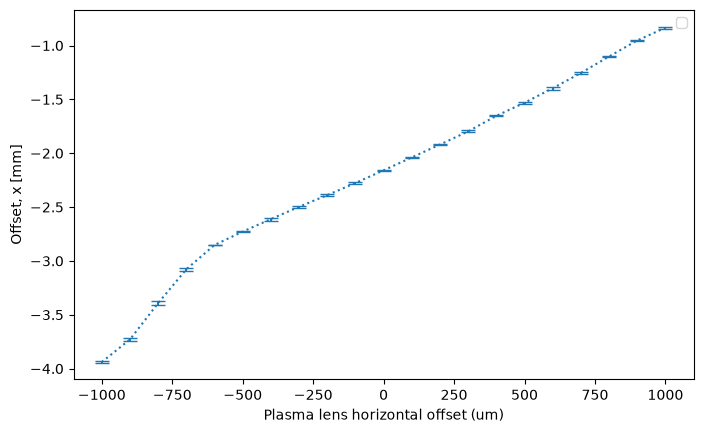

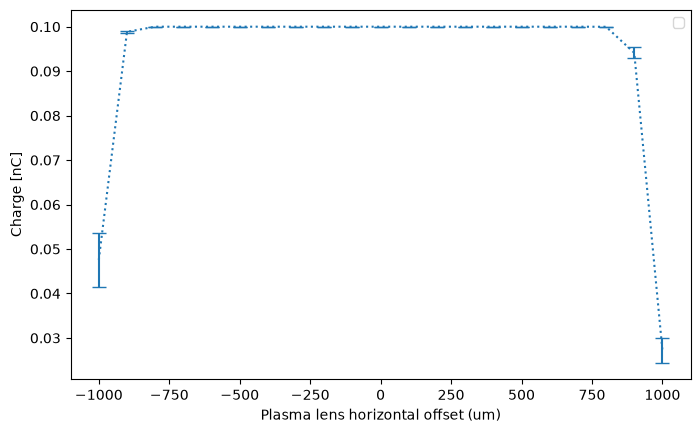

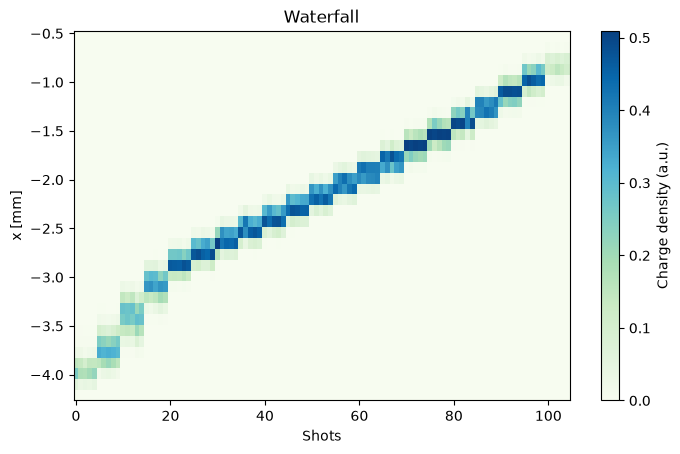

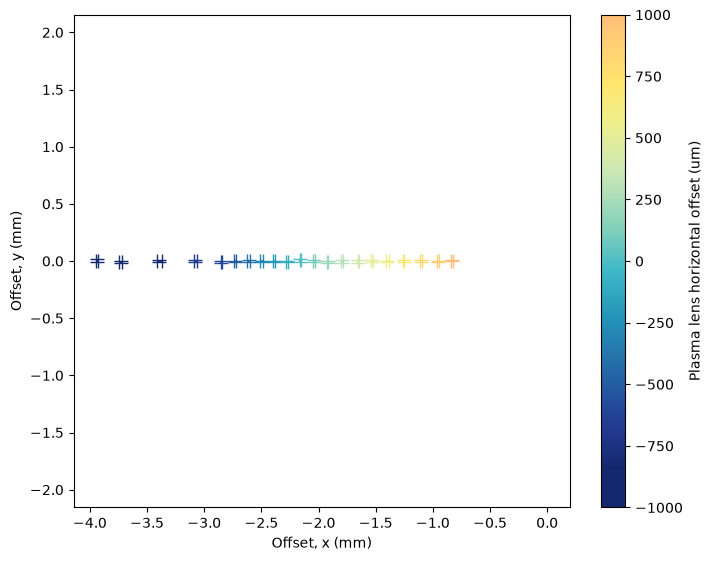

In [7]:
# show outputs
experiment.plot_beam_function(Beam.x_offset, label='Offset, x [mm]', scale=1e-3)
experiment.plot_charge()
experiment.plot_waterfall_x()
experiment.plot_correlation_offsets()